# Detecting Mastitis from Milk Measurements: is machine learning even needed?

**Author:** Abdulsobur Abiola Oladapo (Dapo)  
**Tools:** Python, pandas, SciPy, scikit-learn, seaborn

## Data
`cow_milk_mastitis_dataset.csv`: 800 cows, one row per cow, with milk temperature, pH, electrical conductivity, somatic cell count (SCC), milk yield, a clotting flag, a `Day` column (1–30) and the label `class1` (1 = mastitis). **Source:** Kaggle download (add the dataset link and licence terms here). The raw file is never modified; cleaning happens on an in-memory copy.

> **Units are not documented.** I assume temperature in °C, conductivity in mS/cm, SCC in thousands of cells/mL and yield in litres per day. Conclusions are relative (healthy vs mastitis), so they do not depend on these assumptions.

## Questions
1. How do milk measurements differ between mastitis and healthy cows, and by how much?
2. Can mastitis be detected from them, and is the **100% accuracy** in the original notebook trustworthy?
3. Would a **simple threshold rule** do as well as a machine-learning model?
4. Is the data realistic enough to support real-world claims?

## Key findings (numbers are produced by the cells below)
1. **Mastitis milk looks very different.** Compared with healthy cows, mastitis cows have milk about 2.5 °C warmer, higher pH (7.11 vs 6.65), conductivity 45% higher (6.78 vs 4.69), SCC four times higher (598 vs 148) and yield 54% lower (9.35 vs 20.15). Every difference is enormous (standardised effect size 4.2 to 5.1).
2. **Detection is trivially easy, even without SCC.** A logistic regression on the four non-SCC measurements makes **zero errors in 800 cows** under cross-validation. Any *single* measurement reaches 98.6–99.7% accuracy against a 78.9% "always say healthy" baseline.
3. **A one-line rule works about as well as a model.** For example "milk temperature above 36.8 °C" misclassifies one healthy cow out of 800, and "conductivity above 5.66" misses one mastitis cow.
4. **SCC is a diagnostic criterion, not a stray leak.** The original notebook rightly worried about SCC, but removing it changes nothing because every other measurement separates the classes just as well. The problem is not one leaked column; the whole dataset is too clean.
5. **Clotting is a perfect but incomplete signal:** all 138 clotting cows have mastitis, but 31 of 169 mastitis cows (18%) do not clot.
6. **The data is almost certainly simulated.** Within each class, the measurements are essentially uncorrelated (average |r| = 0.05), while overall they correlate at about 0.80. Real physiology would keep correlations within a class. Published work on real herds reports that conductivity thresholds struggle with low specificity and farm-to-farm variability, which makes a perfect separation here even less realistic.

> The value of this project is the method: show that 100% accuracy is a property of the data, test simple alternatives, and state the limits plainly.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
DATA_PATH = next(p for p in [Path("../data/cow_milk_mastitis_dataset.csv"),
                             Path("data/cow_milk_mastitis_dataset.csv")] if p.exists())
FIG_DIR = Path("../figures") if DATA_PATH.parts[0] == ".." else Path("figures")
FIG_DIR.mkdir(exist_ok=True)
HEALTHY, MASTITIS = "#1F7A6B", "#D9822B"

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load the raw data

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (800, 9)


,Cow_ID,Day,Milk_Temperature,Milk_pH,Milk_Conductivity,Somatic_Cell_Count,Milk_Yield,Clotting,class1
0,C0001,7,35.38,6.49,4.68,148,17.3,0,0
1,C0002,20,35.68,6.46,5.04,101,20.4,0,0
2,C0003,29,34.87,6.84,4.73,206,18.5,0,0
3,C0004,15,36.22,6.69,4.48,96,23.5,0,0
4,C0005,11,35.46,6.56,5.00,142,23.9,0,0


## 3. Cleaning and data dictionary
| Change | Why |
|---|---|
| Rename `class1` to `Mastitis` (1 = mastitis, 0 = healthy) | The original name hides what the label means |
| Add a text `Status` column (Healthy / Mastitis) | Readable chart legends |

No rows are removed and no values are altered.

In [3]:
df = raw.rename(columns={"class1": "Mastitis"}).copy()
df["Status"] = df["Mastitis"].map({0: "Healthy", 1: "Mastitis"})

MEASURES = ["Milk_Temperature", "Milk_pH", "Milk_Conductivity", "Somatic_Cell_Count", "Milk_Yield"]
NO_SCC = [m for m in MEASURES if m != "Somatic_Cell_Count"]
LABELS = {"Milk_Temperature": "Temperature", "Milk_pH": "pH", "Milk_Conductivity": "Conductivity",
          "Somatic_Cell_Count": "SCC", "Milk_Yield": "Yield"}

pd.DataFrame({
    "Column": ["Cow_ID", "Day", "Milk_Temperature", "Milk_pH", "Milk_Conductivity", "Somatic_Cell_Count",
               "Milk_Yield", "Clotting", "Mastitis"],
    "Meaning": ["Cow identifier (one row per cow)", "Day 1-30 (meaning not documented)", "Milk temperature (assumed °C)",
                "Milk acidity", "Electrical conductivity of milk (assumed mS/cm)",
                "Somatic cell count (assumed thousands of cells/mL)", "Milk yield (assumed litres/day)",
                "Clotting observed in milk (1 = yes)", "Target: 1 = mastitis, 0 = healthy"],
})

,Column,Meaning
0,Cow_ID,Cow identifier (one row per cow)
1,Day,Day 1-30 (meaning not documented)
2,Milk_Temperature,Milk temperature (assumed °C)
3,Milk_pH,Milk acidity
4,Milk_Conductivity,Electrical conductivity of milk (assumed mS/cm)
5,Somatic_Cell_Count,Somatic cell count (assumed thousands of cells...
6,Milk_Yield,Milk yield (assumed litres/day)
7,Clotting,Clotting observed in milk (1 = yes)
8,Mastitis,"Target: 1 = mastitis, 0 = healthy"


## 4. Data quality checks

In [4]:
pd.Series({
    "Rows": len(df), "Missing cells": int(df.isna().sum().sum()), "Duplicate rows": int(df.duplicated().sum()),
    "Unique cows": df["Cow_ID"].nunique(), "Mastitis cases": int(df["Mastitis"].sum()),
    "Mastitis share": f"{df['Mastitis'].mean():.1%}",
    "'Always say healthy' accuracy": f"{1 - df['Mastitis'].mean():.1%}",
})

Rows                               800
Missing cells                        0
Duplicate rows                       0
Unique cows                        800
Mastitis cases                     169
Mastitis share                   21.1%
'Always say healthy' accuracy    78.9%
dtype: object

No missing values or duplicates, and each cow appears exactly once, so a random train/test split cannot leak the same cow into both sides. About one in five cows has mastitis, so **accuracy alone is misleading**: always predicting "healthy" is already right 78.9% of the time, which is why I also report recall (the share of mastitis cases caught).

In [5]:
q1, q3 = df[MEASURES].quantile(0.25), df[MEASURES].quantile(0.75)
iqr = q3 - q1
out = (((df[MEASURES] < q1 - 1.5 * iqr) | (df[MEASURES] > q3 + 1.5 * iqr)).sum())
summary = df[MEASURES].describe().T[["min", "mean", "max"]].assign(**{"IQR outliers": out}).round(2)
summary

,min,mean,max,IQR outliers
Milk_Temperature,34.04,36.07,39.38,97
Milk_pH,6.35,6.74,7.42,54
Milk_Conductivity,3.75,5.13,8.09,159
Somatic_Cell_Count,34.00,243.07,1023.00,166
Milk_Yield,4.70,17.87,28.60,4


Ranges look plausible for each measurement. Pooled, the IQR rule flags many cows (54 to 166 for temperature, pH, conductivity and SCC) because the 169 mastitis cows form a second, higher cluster above the healthy ones. These are the sick cows, not recording errors, so **all values are kept**.

### 4.1 The `Day` column carries no signal

In [6]:
print(f"Correlation of Day with mastitis: {df['Day'].corr(df['Mastitis']):.3f}")
print(f"Day, mean by status: {df.groupby('Status')['Day'].mean().round(1).to_dict()}")

Correlation of Day with mastitis: -0.002
Day, mean by status: {'Healthy': 16.0, 'Mastitis': 16.0}


`Day` is unrelated to mastitis (correlation about zero, same average in both groups) and its meaning is undocumented, so I leave it out of the analysis.

### 4.2 Clotting

In [7]:
ct = pd.crosstab(df["Clotting"], df["Status"])
print(ct.to_string())
print(f"\nShare of clotting cows that have mastitis (precision): {ct.loc[1, 'Mastitis'] / ct.loc[1].sum():.0%}")
print(f"Share of mastitis cows that clot (recall): {ct.loc[1, 'Mastitis'] / ct['Mastitis'].sum():.0%}")

Status    Healthy  Mastitis
Clotting                   
0             631        31
1               0       138

Share of clotting cows that have mastitis (precision): 100%
Share of mastitis cows that clot (recall): 82%


Every clotting cow has mastitis, but 31 of the 169 mastitis cows (18%) show no clotting. Clotting is therefore a **perfectly specific but incomplete** sign. It is essentially a second label (a clinical sign of the disease), so I keep it out of the predictors, which matches the original notebook, and now I can say why.

## 5. How do mastitis and healthy milk differ?
For each measurement: group means, percentage difference, **Cohen's d** (difference in pooled standard deviations; 0.8 already counts as "large") and a Mann-Whitney test. Because each cow is one independent row, tests on all 800 rows are valid here.

In [8]:
def cohens_d(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

rows = []
for m in MEASURES:
    h, s = df.loc[df.Mastitis == 0, m], df.loc[df.Mastitis == 1, m]
    rows.append({"Measure": LABELS[m], "Healthy mean": h.mean(), "Mastitis mean": s.mean(),
                 "Difference (%)": 100 * (s.mean() / h.mean() - 1), "Cohen's d": cohens_d(s, h),
                 "p (Mann-Whitney)": stats.mannwhitneyu(s, h)[1]})
diff = pd.DataFrame(rows).set_index("Measure")
diff.round({"Healthy mean": 2, "Mastitis mean": 2, "Difference (%)": 1, "Cohen's d": 2}).assign(
    **{"p (Mann-Whitney)": diff["p (Mann-Whitney)"].map(lambda p: f"{p:.0e}")})

,Healthy mean,Mastitis mean,Difference (%),Cohen's d,p (Mann-Whitney)
Measure,,,,,
Temperature,35.54,38.05,7.1,5.11,8e-89
pH,6.65,7.11,7.0,4.51,1e-88
Conductivity,4.69,6.78,44.6,4.96,8e-89
SCC,147.99,598.05,304.1,4.76,8e-89
Yield,20.15,9.35,-53.6,-4.20,6e-88


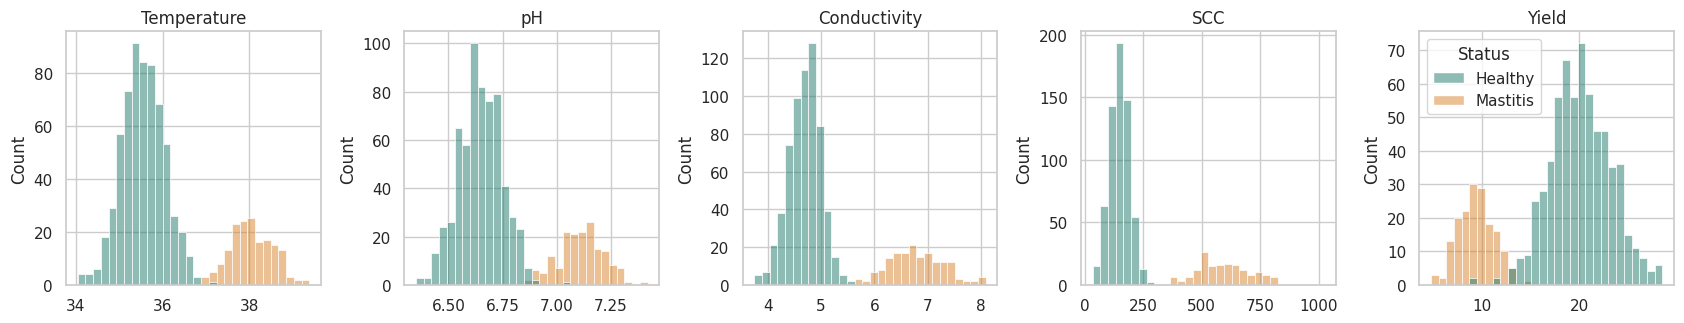

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, m in zip(axes, MEASURES):
    sns.histplot(data=df, x=m, hue="Status", palette={"Healthy": HEALTHY, "Mastitis": MASTITIS},
                 bins=30, ax=ax, legend=(m == MEASURES[-1]), stat="count", common_norm=False)
    ax.set_title(LABELS[m]); ax.set_xlabel("")
plt.tight_layout(); save(fig, "01_distributions_by_status"); plt.show()

The two groups barely overlap on any measurement. Real-world effect sizes for disease markers are usually well below 2; here every one is above 4. The next table counts how many cows fall inside the range where the groups overlap.

In [10]:
rows = {}
for m in MEASURES:
    h, s = df.loc[df.Mastitis == 0, m], df.loc[df.Mastitis == 1, m]
    if s.mean() > h.mean():
        lo, hi = s.min(), h.max()
    else:
        lo, hi = h.min(), s.max()
    lo, hi = min(lo, hi), max(lo, hi)
    n = int(((df[m] >= lo) & (df[m] <= hi)).sum())
    rows[LABELS[m]] = {"Healthy range": f"{h.min():.2f} to {h.max():.2f}", "Mastitis range": f"{s.min():.2f} to {s.max():.2f}",
                       "Cows in overlap zone": n}
pd.DataFrame(rows).T

,Healthy range,Mastitis range,Cows in overlap zone
Temperature,34.04 to 37.10,36.89 to 39.38,5
pH,6.35 to 7.04,6.85 to 7.42,53
Conductivity,3.75 to 5.62,5.38 to 8.09,6
SCC,34.00 to 274.00,235.00 to 1023.00,13
Yield,8.90 to 28.60,4.70 to 15.00,129


Temperature, conductivity and SCC overlap in only 5 to 13 cows out of 800. pH (53) and yield (129) overlap more, but combined with the others the classes are fully separable.

## 6. Is the data realistic?
In real animals, measurements such as temperature, pH, conductivity and SCC stay correlated *within* a health group, because they are driven by the same underlying inflammation. If instead they are independent once the label is known, the data was most likely generated by drawing each measurement separately from a distribution that depends only on the label.

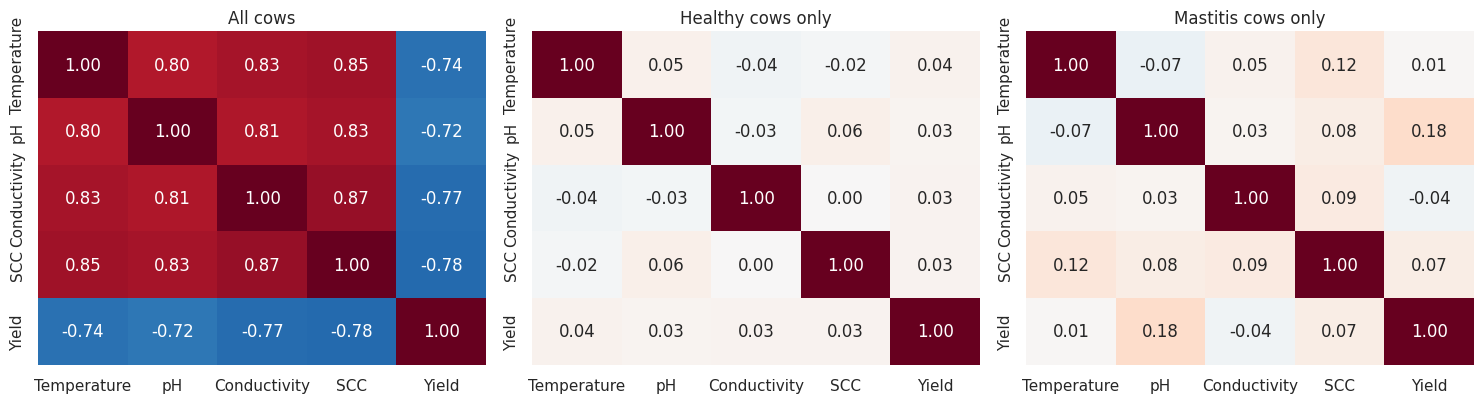

Average |correlation| between measurements: overall = 0.80, within a class = 0.05


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sets = [("All cows", df), ("Healthy cows only", df[df.Mastitis == 0]), ("Mastitis cows only", df[df.Mastitis == 1])]
for ax, (title, d) in zip(axes, sets):
    c = d[MEASURES].rename(columns=LABELS).corr()
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)
plt.tight_layout(); save(fig, "02_within_class_correlation"); plt.show()

iu = np.triu_indices(len(MEASURES), 1)
overall = np.abs(df[MEASURES].corr().values[iu]).mean()
within = np.mean([np.abs(df[df.Mastitis == c][MEASURES].corr().values[iu]).mean() for c in (0, 1)])
print(f"Average |correlation| between measurements: overall = {overall:.2f}, within a class = {within:.2f}")

Overall the measurements correlate strongly (average |r| about 0.80), but **inside each group they are essentially independent** (about 0.05). All the correlation is created by the label itself. This is the signature of **simulated data**. Together with the tiny within-group spreads (for example, milk temperature has a standard deviation of only 0.49 °C in both groups), it means the "perfect" classification reflects how the data was generated, not how mastitis behaves in a real herd.

## 7. Modelling
### 7.1 The original approach, and what I changed
The original notebook used one 80/20 split (160 test cows, only 34 with mastitis) and reported accuracy 1.0. I replaced it with **5-fold stratified cross-validation repeated 3 times** (15 test sets, class ratio preserved) and report **accuracy, recall, precision and AUC**. Logistic regression is wrapped with a scaler. I compare three feature sets: all five measurements, the four without SCC (no diagnostic-criterion risk), and each measurement alone.

In [12]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Recall": "recall", "Precision": "precision", "AUC": "roc_auc"}
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

def evaluate(model, cols):
    res = cross_validate(model, df[cols], df["Mastitis"], cv=cv, scoring=scoring)
    return {k: res[f"test_{k}"].mean() for k in scoring}

table = {
    "Logistic, all 5 measures": evaluate(lr, MEASURES),
    "Logistic, 4 without SCC": evaluate(lr, NO_SCC),
    "Random forest, 4 without SCC": evaluate(rf, NO_SCC),
}
for m in MEASURES:
    table[f"Logistic, {LABELS[m]} alone"] = evaluate(lr, [m])
results = pd.DataFrame(table).T
results.round(4)

,Accuracy,Recall,Precision,AUC
"Logistic, all 5 measures",1.0000,1.0000,1.0000,1.0000
"Logistic, 4 without SCC",1.0000,1.0000,1.0000,1.0000
"Random forest, 4 without SCC",0.9988,1.0000,0.9942,1.0000
"Logistic, Temperature alone",0.9962,0.9882,0.9942,1.0000
"Logistic, pH alone",0.9879,0.9584,0.9845,0.9994
"Logistic, Conductivity alone",0.9967,0.9842,1.0000,1.0000
"Logistic, SCC alone",0.9962,0.9822,1.0000,0.9999
"Logistic, Yield alone",0.9863,0.9684,0.9673,0.9973


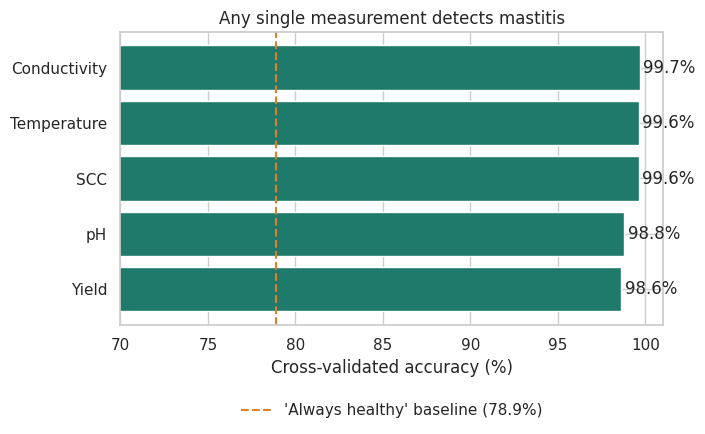

In [13]:
single_acc = results.loc[[f"Logistic, {LABELS[m]} alone" for m in MEASURES], "Accuracy"]
single_acc.index = [LABELS[m] for m in MEASURES]
baseline = 1 - df["Mastitis"].mean()

fig, ax = plt.subplots(figsize=(7, 3.8))
order = single_acc.sort_values().index
ax.barh(order, single_acc[order] * 100, color=HEALTHY)
ax.axvline(baseline * 100, color=MASTITIS, ls="--", label=f"'Always healthy' baseline ({baseline:.1%})")
ax.set_xlim(70, 101); ax.set_xlabel("Cross-validated accuracy (%)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
for y, v in enumerate(single_acc[order] * 100):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center")
ax.set_title("Any single measurement detects mastitis")
save(fig, "03_single_measure_accuracy"); plt.show()

- **Removing SCC changes nothing:** logistic regression stays perfect (accuracy and recall 1.00) and the random forest is at about 99.9%.
- **Any single measurement is enough** (98.6% to 99.7% accuracy against the 78.9% baseline).
- So the original notebook's instinct to drop SCC was reasonable, but it was fixing the wrong problem. SCC is the usual diagnostic criterion for mastitis, so it overlaps the label by definition, but even without it the other measurements are just as informative. The issue is that **the entire dataset is too separable**.

### 7.2 Do we need a model? Simple threshold rules
A decision "stump" finds the single best cut-off for one measurement. The table shows the cut-off and the number of mistakes on all 800 cows.

In [14]:
rules = []
for m in MEASURES:
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(df[[m]], df["Mastitis"])
    thr = stump.tree_.threshold[0]
    higher_is_mastitis = df.loc[df.Mastitis == 1, m].mean() > df.loc[df.Mastitis == 0, m].mean()
    pred = (df[m] > thr).astype(int) if higher_is_mastitis else (df[m] <= thr).astype(int)
    fn = int(((pred == 0) & (df.Mastitis == 1)).sum())
    fp = int(((pred == 1) & (df.Mastitis == 0)).sum())
    cv_acc = cross_validate(DecisionTreeClassifier(max_depth=1, random_state=SEED), df[[m]], df["Mastitis"],
                            cv=cv, scoring="accuracy")["test_score"].mean()
    rules.append({"Rule": f"{LABELS[m]} {'>' if higher_is_mastitis else '<='} {thr:.2f}",
                  "Missed mastitis (FN)": fn, "False alarms (FP)": fp, "CV accuracy": round(cv_acc, 3)})
pd.DataFrame(rules).set_index("Rule")

,Missed mastitis (FN),False alarms (FP),CV accuracy
Rule,,,
Temperature > 36.84,0,1,0.998
pH > 6.88,2,3,0.994
Conductivity > 5.66,1,0,0.998
SCC > 278.00,1,0,0.997
Yield <= 13.45,1,9,0.985


A single cut-off on temperature or conductivity makes only **one mistake in 800 cows**, which is as good as the machine-learning models and far easier to explain, audit and use on a farm. If a model adds nothing over a threshold, the threshold is the better tool. The right choice between rules also depends on the cost of errors: a **missed mastitis case** (false negative) usually costs more than a **false alarm**, so a real deployment would tune the cut-off to favour recall.

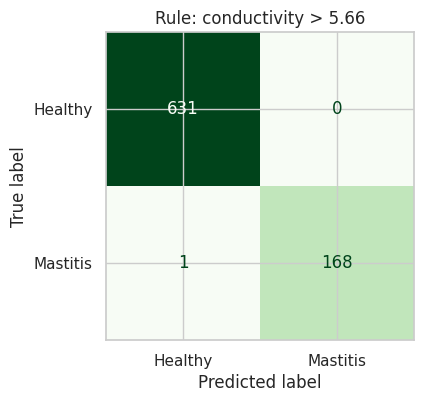

In [15]:
rule_pred = (df["Milk_Conductivity"] > 5.66).astype(int)
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(df["Mastitis"], rule_pred, display_labels=["Healthy", "Mastitis"],
                                        cmap="Greens", colorbar=False, ax=ax)
ax.set_title("Rule: conductivity > 5.66")
save(fig, "04_conductivity_rule_confusion"); plt.show()

### 7.3 Which measurement matters most? (scaled coefficients)

The original coefficient chart used unscaled features, so measurements in different units were not comparable. With features standardised, each coefficient shows the effect of a one-standard-deviation change.

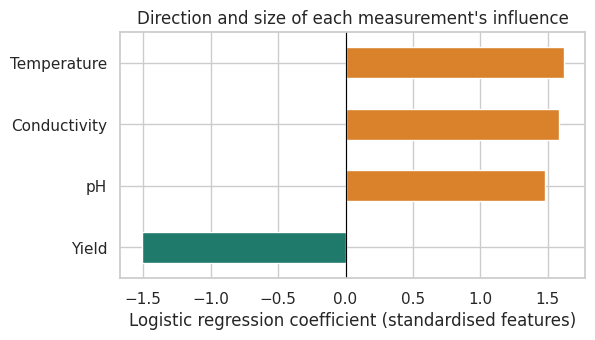

{'Yield': -1.51, 'pH': 1.48, 'Conductivity': 1.59, 'Temperature': 1.62}

In [16]:
lr_fit = lr.fit(df[NO_SCC], df["Mastitis"])
coef = pd.Series(lr_fit[-1].coef_[0], index=[LABELS[m] for m in NO_SCC]).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.2))
coef.plot.barh(color=[MASTITIS if v > 0 else HEALTHY for v in coef], ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Logistic regression coefficient (standardised features)")
ax.set_title("Direction and size of each measurement's influence")
save(fig, "05_standardised_coefficients"); plt.show()
coef.round(2).to_dict()

Higher temperature, pH and conductivity raise the predicted mastitis probability, and higher yield lowers it, all with similar weight (about 1.5 each). The coefficients are nearly equal because every measurement is separated from the label by about the same distance, which is again what a simulated dataset looks like. (With real data, correlated measurements would trade off against each other and the weights would differ.)

## 8. What this means
1. **Mastitis, in this dataset, is easy to flag** from milk temperature, conductivity, pH, SCC or yield, and a single threshold is enough.
2. **Do not over-interpret 100%.** It shows that the label and the measurements were generated together, not that a model has learned mastitis.
3. **If this data were real**, I would deploy a threshold rule, tuned to favour catching cases, and monitor it, rather than a black-box model.

## 9. Limitations
- **The data looks simulated** (independence within groups, tiny spreads, perfect separation), so none of the accuracy figures describe real herd performance.
- **One measurement per cow**: no repeated measures over time, so early detection or progression cannot be studied.
- **Undocumented units and `Day`**; no breed, parity, farm or lactation-stage information.
- **A single group of cows**: generalisation to other farms is untested.
- **Clinical vs subclinical mastitis is not distinguished**, and the source of the label is unknown.

## 10. Next steps
- Repeat on real farm data with repeated measures per cow and a farm-level hold-out.
- Compare thresholds and models on recall at a fixed false-alarm rate rather than raw accuracy.
- Study early detection: can measurements flag mastitis days before clinical signs?
- Wrap the threshold rule or model in a small app for farm use.

## Background reading
Pan et al., *Machine learning-based clinical mastitis detection in dairy cows using milk electrical conductivity and somatic cell count*, Frontiers in Veterinary Science (2025), doi:10.3389/fvets.2025.1671186. The authors note that conductivity thresholds are limited by low specificity and farm-specific variability, which is a useful contrast with how clean this dataset is.

---
*Data: cow_milk_mastitis_dataset.csv (Kaggle download; add source link and licence terms).*

## Appendix: plain-language summary chart
Used in the report and README: (A) conductivity against yield for each cow; (B) the single-measurement accuracy from section 7.1.

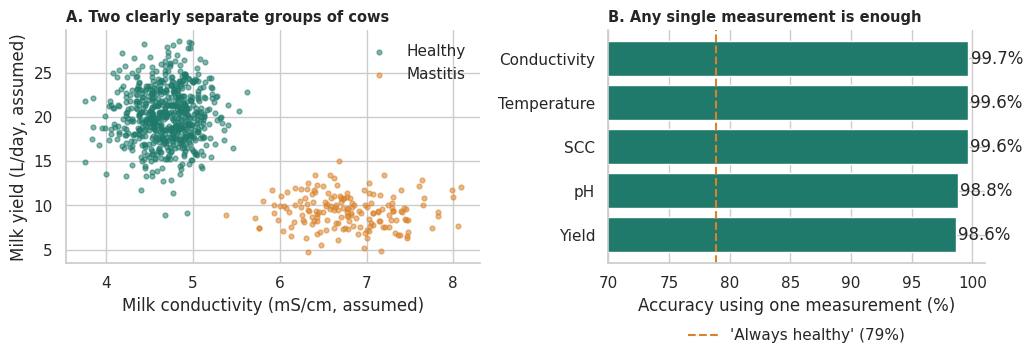

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})
for status, color in [("Healthy", HEALTHY), ("Mastitis", MASTITIS)]:
    d = df[df.Status == status]
    ax[0].scatter(d["Milk_Conductivity"], d["Milk_Yield"], s=12, alpha=0.55, color=color, label=status)
ax[0].set_xlabel("Milk conductivity (mS/cm, assumed)"); ax[0].set_ylabel("Milk yield (L/day, assumed)")
ax[0].legend(frameon=False)
ax[0].set_title("A. Two clearly separate groups of cows", fontsize=10.5, loc="left", fontweight="bold")

order = single_acc.sort_values().index
ax[1].barh(order, single_acc[order] * 100, color=HEALTHY)
ax[1].axvline(baseline * 100, color=MASTITIS, ls="--", label=f"'Always healthy' ({baseline:.0%})")
ax[1].set_xlim(70, 101); ax[1].set_xlabel("Accuracy using one measurement (%)"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
for y, v in enumerate(single_acc[order] * 100):
    ax[1].text(v + 0.2, y, f"{v:.1f}%", va="center")
ax[1].set_title("B. Any single measurement is enough", fontsize=10.5, loc="left", fontweight="bold")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); save(fig, "06_summary_chart"); plt.show()